In [ ]:
# Iteración 1: entrenamiento con el dataset tal como viene de Roboflow (sin limpiar).
# Esta celda ya fue ejecutada por el equipo en Colab; sus resultados están en la salida de abajo.
# Para repetirla se necesita acceso al proyecto de Roboflow (clave guardada en los Secretos de Colab
# con el nombre ROBOFLOW_API_KEY; nunca escribirla en el cuaderno).
!pip install -q roboflow ultralytics
from google.colab import userdata
from roboflow import Roboflow
from ultralytics import YOLO

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
dataset = rf.workspace("emanuel-leonardo-mejias-torres").project("capstone-s2mpp").version(1).download("yolov11")

model = YOLO("yolo11n.pt")
results = model.train(data=f"{dataset.location}/data.yaml", epochs=50, imgsz=640)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 100.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 10.1 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Capstone-1 in yolov11:: 100%|██████████| 1909/1909 [00:00<00:00, 7413.61it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Capstone-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, 

# Proyecto Capstone: Clasificación Inteligente de Residuos Reciclables mediante Visión por Computadora (YOLOv11)

## 1. Fase 1: Entendimiento del Negocio (CRISP-DM)

### 1.1 Contexto y Problemática
La baja tasa de valorización de residuos domiciliarios e industriales se debe, en gran medida, a la incorrecta separación en origen por parte de los usuarios (contaminación cruzada en puntos limpios). Automatizar la identificación de materiales reciclables mediante visión artificial permite asistir a los usuarios en tiempo real e incrementar la eficiencia del reciclaje.

### 1.2 Objetivos del Negocio
* **Objetivo General:** Desarrollar e integrar un sistema de detección y clasificación automática de residuos reciclables (**Aluminio**, **Cartón** y **Plástico**) utilizando redes neuronales profundas para facilitar la separación en origen.
* **Objetivos Específicos:**
  1. Construir y curar un dataset etiquetado representativo de las tres clases objetivo.
  2. Entrenar un modelo ligero de detección de objetos capaz de ejecutarse con baja latencia en una aplicación web o dispositivo móvil.

### 1.3 Criterios de Éxito Técnico (Data Mining Goals)
* **Precisión de Detección (`mAP@50`):** Alcanzar un `mAP50` global $\ge 0.65$ en el conjunto de validación/prueba.
* **Velocidad de Inferencia:** Tiempo de inferencia inferior a $100\text{ ms}$ por imagen en GPU/CPU para permitir respuesta casi en tiempo real.

Descargando dataset nuevamente desde Roboflow...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.1 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Capstone-1 in yolov11:: 100%|██████████| 1909/1909 [00:00<00:00, 7533.71it/s]


Conteo en Train: {'Plastico': 568, 'Carton': 572, 'Aluminio': 316}
Conteo en Valid: {'Carton': 51, 'Plastico': 42, 'Aluminio': 16}


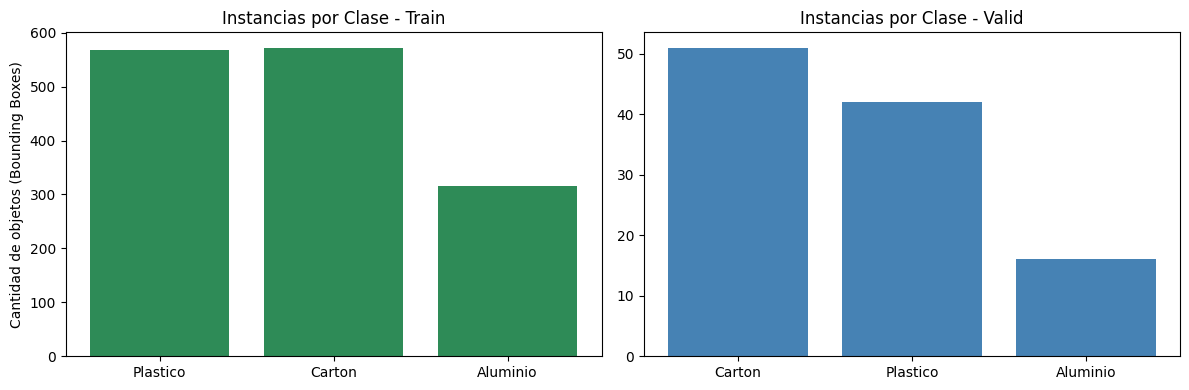

In [ ]:
import os
import yaml
from collections import Counter
import matplotlib.pyplot as plt

# 1. Definir la ruta donde Roboflow descarga el proyecto
dataset_path = "/content/Capstone-1"

# Si la sesión de Colab se reinició y se borró la carpeta, la descargamos de nuevo
if not os.path.exists(f"{dataset_path}/data.yaml"):
    print("Descargando dataset nuevamente desde Roboflow...")
    try:
        from roboflow import Roboflow
    except ImportError:
        !pip install -q roboflow
        from roboflow import Roboflow

    try:
        ROBOFLOW_API_KEY
    except NameError:
        from getpass import getpass
        try:
            from google.colab import userdata
            ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
        except Exception:
            ROBOFLOW_API_KEY = os.environ.get("ROBOFLOW_API_KEY") or getpass("Roboflow API key: ")
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    project = rf.workspace("emanuel-leonardo-mejias-torres").project("capstone-s2mpp")
    version = project.version(1)
    dataset = version.download("yolov11")
    dataset_path = dataset.location

# 2. Leer configuración del dataset
with open(f"{dataset_path}/data.yaml", 'r') as f:
    data_yaml = yaml.safe_load(f)

clases = data_yaml['names']

# 3. Contar instancias por cada partición (train, valid, test)
def contar_instancias(split):
    ruta_labels = f"{dataset_path}/{split}/labels"
    conteo = Counter()
    if not os.path.exists(ruta_labels):
        return conteo
    for archivo in os.listdir(ruta_labels):
        if archivo.endswith(".txt"):
            with open(os.path.join(ruta_labels, archivo), 'r') as f:
                for linea in f:
                    partes = linea.strip().split()
                    if partes:
                        clase_id = int(partes[0])
                        nombre_clase = clases[clase_id] if isinstance(clases, list) else clases.get(clase_id, str(clase_id))
                        conteo[nombre_clase] += 1
    return conteo

train_counts = contar_instancias("train")
val_counts = contar_instancias("valid")

print("Conteo en Train:", dict(train_counts))
print("Conteo en Valid:", dict(val_counts))

# 4. Graficar distribución
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(train_counts.keys(), train_counts.values(), color='seagreen')
ax[0].set_title("Instancias por Clase - Train")
ax[0].set_ylabel("Cantidad de objetos (Bounding Boxes)")

ax[1].bar(val_counts.keys(), val_counts.values(), color='steelblue')
ax[1].set_title("Instancias por Clase - Valid")
plt.tight_layout()
plt.show()

## 2. Fase 2: Entendimiento de los Datos (Conclusiones del EDA)

A partir de la exploración cuantitativa y visual del dataset descargado desde Roboflow (`860` imágenes de entrenamiento y `61` de validación), se identifican los siguientes hallazgos clave:

1. **Distribución y Desbalance de Clases:**
   * **Entrenamiento (`1,456` instancias):** Existe paridad entre **Cartón** (`572` instancias, $39.3\%$) y **Plástico** (`568` instancias, $39.0\%$), mientras que **Aluminio** presenta una menor representación (`316` instancias, $21.7\%$).
   * **Validación (`109` instancias):** Se mantiene la proporción con `51` instancias de **Cartón**, `42` de **Plástico** y `16` de **Aluminio**.
2. **Complejidad Intraclase:** A pesar de que `Plastico` cuenta con una alta cantidad de muestras, presenta alta variabilidad visual (transparencia en botellas PET, deformaciones y brillos), lo que exige técnicas de *Data Augmentation* robustas.
3. **Inconsistencia en Formato de Anotaciones (Hallazgo Crítico):** Se detectó una mezcla de etiquetas de detección (*Bounding Boxes* de 4 coordenadas) y polígonos de segmentación (`628` en *train* y `44` en *valid*). Sin un preprocesamiento previo, el motor de entrenamiento descarta los polígonos, perdiendo más del $40\%$ de las etiquetas útiles.

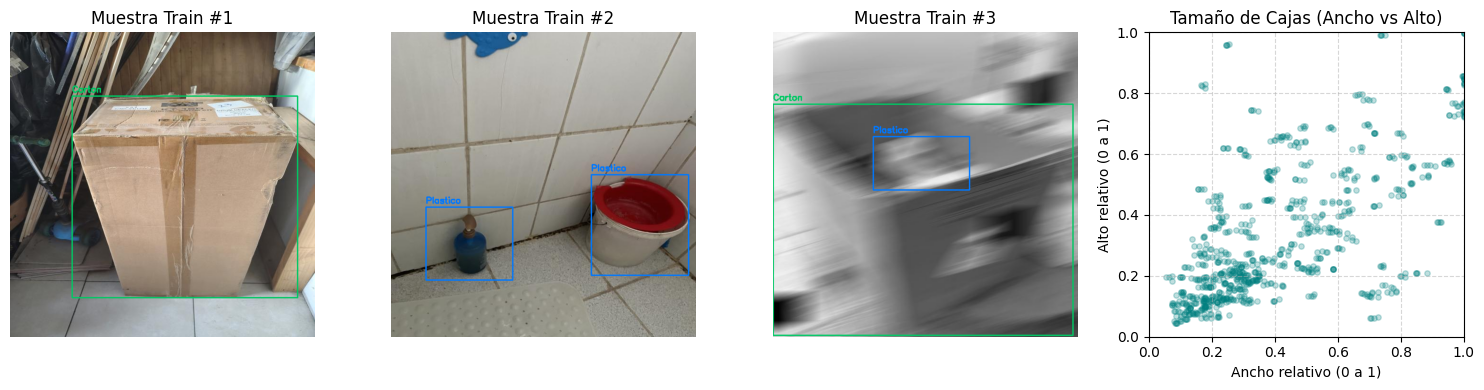

In [ ]:
import cv2
import glob
import numpy as np
import matplotlib.pyplot as plt

# 1. Analizar dimensiones de las cajas delimitadoras (ancho vs alto normalizado)
anchos, altos = [], []
for txt_file in glob.glob(f"{dataset_path}/train/labels/*.txt"):
    with open(txt_file, 'r') as f:
        for line in f:
            parts = line.strip().split()
            # Solo tomamos formato estándar de caja YOLO: clase x_center y_center width height (5 valores)
            if len(parts) == 5:
                anchos.append(float(parts[3]))
                altos.append(float(parts[4]))

# 2. Visualizar 3 imágenes de entrenamiento con sus Bounding Boxes y el mapa de tamaños
fig = plt.figure(figsize=(15, 4))

imagenes_muestra = glob.glob(f"{dataset_path}/train/images/*.jpg")[:3]
colores = {0: (255, 100, 0), 1: (0, 200, 100), 2: (0, 120, 255)}

for idx, img_path in enumerate(imagenes_muestra):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    label_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                parts = [float(x) for x in line.strip().split()]
                cls_id = int(parts[0])
                nombre_cls = clases[cls_id] if isinstance(clases, list) else clases.get(cls_id, str(cls_id))

                # Si tiene 5 valores es Bounding Box; si tiene más es Polígono y calculamos su caja envolvente
                if len(parts) == 5:
                    xc, yc, bw, bh = parts[1], parts[2], parts[3], parts[4]
                    x1, y1 = int((xc - bw/2) * w), int((yc - bh/2) * h)
                    x2, y2 = int((xc + bw/2) * w), int((yc + bh/2) * h)
                else:
                    xs = parts[1::2]
                    ys = parts[2::2]
                    x1, y1 = int(min(xs) * w), int(min(ys) * h)
                    x2, y2 = int(max(xs) * w), int(max(ys) * h)

                cv2.rectangle(img, (x1, y1), (x2, y2), colores.get(cls_id, (255, 255, 0)), 2)
                cv2.putText(img, nombre_cls, (x1, max(y1 - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, colores.get(cls_id, (255, 255, 0)), 2)

    ax = fig.add_subplot(1, 4, idx + 1)
    ax.imshow(img)
    ax.set_title(f"Muestra Train #{idx+1}")
    ax.axis("off")

# Gráfico de dispersión de tamaños de cajas
ax_size = fig.add_subplot(1, 4, 4)
ax_size.scatter(anchos, altos, alpha=0.25, color='teal', s=15)
ax_size.set_title("Tamaño de Cajas (Ancho vs Alto)")
ax_size.set_xlabel("Ancho relativo (0 a 1)")
ax_size.set_ylabel("Alto relativo (0 a 1)")
ax_size.set_xlim(0, 1)
ax_size.set_ylim(0, 1)
ax_size.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 2.1 Geometría de los objetos: escala MS-COCO y relación de aspecto

La geometría de los objetos se clasifica según el estándar MS-COCO (pequeños $<32^2$ px, medianos entre $32^2$ y $96^2$ px y grandes $>96^2$ px, en una grilla de $640 \times 640$) y se estudia la relación de aspecto ($\text{Ratio} = \frac{\text{Ancho}}{\text{Alto}}$) para justificar la configuración de los cabezales de detección (*anchor-free* con DFL).

The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


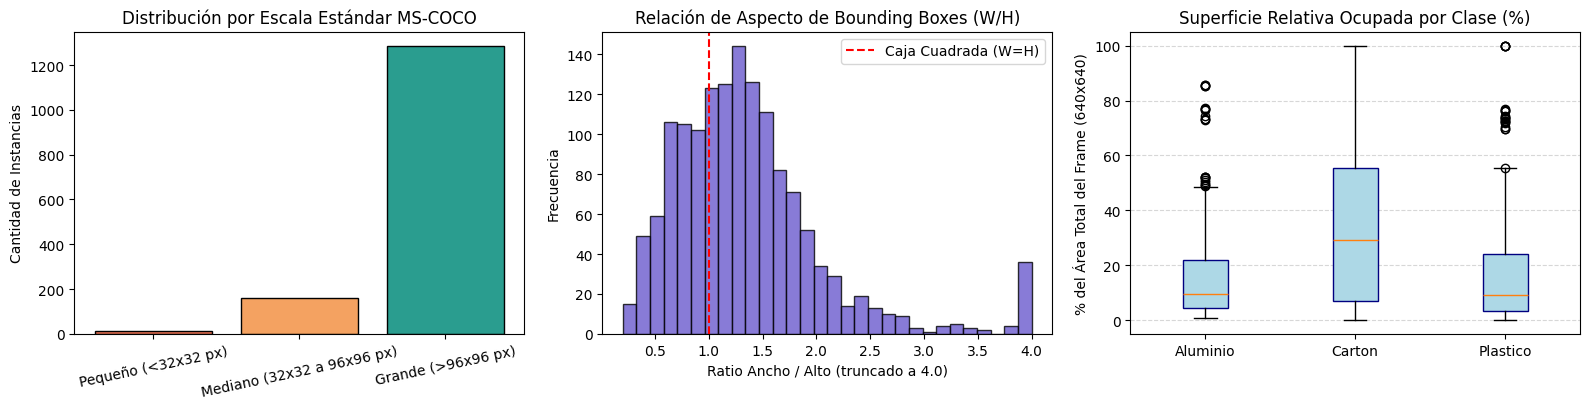

In [ ]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Análisis geométrico avanzado bajo estándar MS-COCO (escalado a 640x640)
IMG_SIZE = 640
aspect_ratios = []
coco_scales = {"Pequeño (<32x32 px)": 0, "Mediano (32x32 a 96x96 px)": 0, "Grande (>96x96 px)": 0}
areas_por_clase = {nombre: [] for nombre in (clases if isinstance(clases, list) else clases.values())}

for txt_file in glob.glob(f"{dataset_path}/train/labels/*.txt"):
    with open(txt_file, 'r') as f:
        for line in f:
            parts = [float(x) for x in line.strip().split()]
            if len(parts) == 5:
                cls_id, xc, yc, bw, bh = int(parts[0]), parts[1], parts[2], parts[3], parts[4]
                if bw > 0 and bh > 0:
                    # Relación de aspecto (Ancho / Alto)
                    aspect_ratios.append(bw / bh)

                    # Área en píxeles reales a resolución 640x640
                    area_px = (bw * IMG_SIZE) * (bh * IMG_SIZE)
                    if area_px < (32 ** 2):
                        coco_scales["Pequeño (<32x32 px)"] += 1
                    elif area_px <= (96 ** 2):
                        coco_scales["Mediano (32x32 a 96x96 px)"] += 1
                    else:
                        coco_scales["Grande (>96x96 px)"] += 1

                    nombre_cls = clases[cls_id] if isinstance(clases, list) else clases.get(cls_id, str(cls_id))
                    areas_por_clase[nombre_cls].append(bw * bh * 100) # % del área de la imagen

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

# 1. Clasificación de objetos según estándar MS-COCO
ax[0].bar(coco_scales.keys(), coco_scales.values(), color=['#e76f51', '#f4a261', '#2a9d8f'], edgecolor='black')
ax[0].set_title("Distribución por Escala Estándar MS-COCO")
ax[0].set_ylabel("Cantidad de Instancias")
ax[0].tick_params(axis='x', rotation=12)

# 2. Distribución de Relación de Aspecto (Aspect Ratio = W/H)
ax[1].hist(np.clip(aspect_ratios, 0, 4), bins=30, color='slateblue', edgecolor='black', alpha=0.8)
ax[1].axvline(1.0, color='red', linestyle='--', label='Caja Cuadrada (W=H)')
ax[1].set_title("Relación de Aspecto de Bounding Boxes (W/H)")
ax[1].set_xlabel("Ratio Ancho / Alto (truncado a 4.0)")
ax[1].set_ylabel("Frecuencia")
ax[1].legend()

# 3. Boxplot de superficie ocupada por tipo de residuo
ax[2].boxplot(areas_por_clase.values(), labels=areas_por_clase.keys(), patch_artist=True,
              boxprops=dict(facecolor='lightblue', color='navy'))
ax[2].set_title("Superficie Relativa Ocupada por Clase (%)")
ax[2].set_ylabel("% del Área Total del Frame (640x640)")
ax[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 3. Fase 3: Preparación de los Datos

### 3.1 Estandarización de etiquetas (polígonos → *bounding boxes*)

Se convierten a cajas delimitadoras las anotaciones de segmentación (polígonos) que venían mezcladas con las de detección, para que el motor de entrenamiento no las descarte.

In [ ]:
import glob

# Fase 3 CRISP-DM: Limpieza y estandarización de etiquetas (Polígonos -> Bounding Boxes)
def convertir_poligonos_a_cajas(ruta_base):
    archivos_txt = glob.glob(f"{ruta_base}/*/labels/*.txt")
    convertidos = 0
    for txt in archivos_txt:
        nuevas_lineas = []
        modificado = False
        with open(txt, 'r') as f:
            for linea in f:
                partes = [float(x) for x in linea.strip().split()]
                if len(partes) > 5:  # Es un polígono de segmentación
                    cls_id = int(partes[0])
                    xs = partes[1::2]
                    ys = partes[2::2]
                    xmin, xmax = min(xs), max(xs)
                    ymin, ymax = min(ys), max(ys)
                    xc = (xmin + xmax) / 2.0
                    yc = (ymin + ymax) / 2.0
                    bw = xmax - xmin
                    bh = ymax - ymin
                    nuevas_lineas.append(f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")
                    modificado = True
                elif len(partes) == 5:
                    nuevas_lineas.append(linea)
        if modificado:
            convertidos += 1
            with open(txt, 'w') as f:
                f.writelines(nuevas_lineas)
    print(f"Limpieza completada: {convertidos} archivos con polígonos fueron estandarizados a Bounding Boxes.")

convertir_poligonos_a_cajas(dataset_path)

Limpieza completada: 485 archivos con polígonos fueron estandarizados a Bounding Boxes.


### 3.2 Balanceo de la clase minoritaria (`Aluminio`) por *oversampling*

`Aluminio` tiene menor representación en entrenamiento (`316` instancias frente a `572` de `Carton`) y, según la matriz de confusión inicial, presenta más falsos negativos contra el fondo. Para compensarlo se aplica *oversampling*: cada imagen de entrenamiento que contiene `Aluminio` se duplica con un volteo horizontal (la coordenada $x$ se ajusta como $x' = 1 - x$). Solo se modifica el conjunto de entrenamiento; el de validación no se toca.

In [ ]:
import glob
import os
import shutil
import cv2

# 1. Identificar el ID de la clase 'Aluminio' en data.yaml
id_aluminio = 0
for k, v in ( enumerate(clases) if isinstance(clases, list) else clases.items() ):
    if "aluminio" in v.lower():
        id_aluminio = int(k)

# 2. Aplicar Oversampling (Duplicación espejada) solo a imágenes con Aluminio en Train
archivos_train = glob.glob(f"{dataset_path}/train/labels/*.txt")
nuevas_copias = 0

for txt_path in archivos_train:
    # Evitar duplicar copias si se corre dos veces
    if "_oversample_alu" in txt_path:
        continue

    with open(txt_path, 'r') as f:
        lineas = [l.strip().split() for l in f if l.strip()]

    # Verificar si esta imagen contiene al menos un objeto de Aluminio
    tiene_aluminio = any(int(float(p[0])) == id_aluminio for p in lineas if len(p) == 5)

    if tiene_aluminio:
        img_path = txt_path.replace("/labels/", "/images/").rsplit(".", 1)[0] + ".jpg"
        if os.path.exists(img_path):
            # Guardar imagen volteada horizontalmente (Flip Horizontal)
            img = cv2.imread(img_path)
            img_flip = cv2.flip(img, 1)
            nuevo_img_path = img_path.replace(".jpg", "_oversample_alu.jpg")
            cv2.imwrite(nuevo_img_path, img_flip)

            # Ajustar coordenada X (x_nuevo = 1.0 - x_original) en el archivo .txt
            nuevo_txt_path = txt_path.replace(".txt", "_oversample_alu.txt")
            with open(nuevo_txt_path, 'w') as f_out:
                for p in lineas:
                    if len(p) == 5:
                        cls_id = int(float(p[0]))
                        xc = 1.0 - float(p[1])
                        yc, bw, bh = float(p[2]), float(p[3]), float(p[4])
                        f_out.write(f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")
            nuevas_copias += 1

# Borrar caché para que YOLO reconozca el dataset balanceado
for cache_file in glob.glob(f"{dataset_path}/*/*.cache"):
    os.remove(cache_file)

print(f"✅ Balanceo completado: Se agregaron {nuevas_copias} imágenes de refuerzo para Aluminio.")


✅ Balanceo completado: Se agregaron 252 imágenes de refuerzo para Aluminio.


## 4. Fase 4: Modelado (Fine-Tuning de YOLOv11n)
Se selecciona la arquitectura **YOLOv11n (Nano)** aplicando *Transfer Learning* desde los pesos preentrenados en COCO (`yolo11n.pt`). Luego de estandarizar los 485 archivos con polígonos a *Bounding Boxes*, se entrena el modelo durante 50 épocas a una resolución de $640 \times 640$ píxeles.

### 4.1 Entrenamiento de la iteración 2 (dataset limpio y balanceado)

Se borran los archivos `.cache` para que YOLO lea las etiquetas ya estandarizadas (485 archivos corregidos) y el conjunto balanceado, y se entrena `yolo11n.pt` durante 50 épocas con imágenes de $640 \times 640$.

In [ ]:
import glob
import os

# 1. Borrar caché previa si existe para que YOLO cargue los 485 archivos corregidos
for cache_file in glob.glob(f"{dataset_path}/*/*.cache"):
    os.remove(cache_file)

# 2. Instalar/Cargar Ultralytics y entrenar YOLOv11n
try:
    from ultralytics import YOLO
except ImportError:
    !pip install -q ultralytics
    from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data=f"{dataset_path}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project="/content/runs/detect",
    name="ecoscan_yolo11n",
    exist_ok=True
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 8.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Capstone-1/data.yaml, degrees=0.0, deterministi

### 4.2 Fundamentación Arquitectónica y Función de Costo Compuesta (YOLOv11n)

A nivel estructural, **YOLOv11n** introduce dos bloques clave frente a generaciones previas (YOLOv8) que optimizan la extracción de características en residuos con deformaciones y reflejos:
1. **Bloque `C3k2` (Cross Stage Partial con kernel $2\times2$):** Reemplaza el bloque `C2f` reduciendo el costo computacional ($6.4\text{ GFLOPs}$ y $2.58\text{M}$ de parámetros) sin perder campo receptivo.
2. **Módulo `C2PSA` (Cross Stage Partial with Pointwise Spatial Attention):** Ubicado tras la capa `SPPF`, aplica atención espacial para que la red enfoque sus pesos en bordes relevantes (ej. contornos de botellas PET transparentes o latas abolladas) discriminando el fondo complejo.

#### Optimización Multi-Tarea (Loss Function)
El ajuste fino (*fine-tuning*) minimiza una función de pérdida ponderada compuesta por tres términos:

$$\mathcal{L}_{\text{total}} = \lambda_{\text{box}}\mathcal{L}_{\text{CIoU}} + \lambda_{\text{cls}}\mathcal{L}_{\text{BCE}} + \lambda_{\text{dfl}}\mathcal{L}_{\text{DFL}}$$

* **$\mathcal{L}_{\text{CIoU}}$ (*Complete Intersection over Union* — $\lambda_{\text{box}} = 7.5$):** Penaliza simultáneamente el solapamiento del área, la distancia euclidiana entre centros y la diferencia en la relación de aspecto $(w/h)$ de las cajas.
* **$\mathcal{L}_{\text{BCE}}$ (*Binary Cross-Entropy* — $\lambda_{\text{cls}} = 0.5$):** Evalúa la probabilidad de pertenencia a las clases `Aluminio`, `Carton` y `Plastico`.
* **$\mathcal{L}_{\text{DFL}}$ (*Distribution Focal Loss* — $\lambda_{\text{dfl}} = 1.5$):** Modela las coordenadas de los bordes de la caja como una distribución continua en lugar de un valor determinista único, crucial para límites difusos o residuos parcialmente ocluidos.

## 5. Fase 5: Evaluación del Modelo
Se evalúa el rendimiento del modelo ajustado (`best.pt`) sobre el conjunto de validación/prueba analizando Precisión ($P$), Recall ($R$), `mAP@50`, `mAP@50-95`, curvas de pérdida y la matriz de confusión normalizada.

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1152.4±422.8 MB/s, size: 41.8 KB)
val: Scanning /content/Capstone-1/valid/labels.cache... 61 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 61/61 15.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.5it/s 2.7s
                   all         61        109      0.681      0.521      0.562      0.323
              Aluminio         15         16      0.654        0.5      0.493      0.235
                Carton         32         51      0.789      0.659      0.737      0.498
              Plastico         27         42        0.6      0.405      0.454      0.236
Speed: 6.7ms preprocess, 10.2ms inference, 0.0ms loss, 4.3ms postprocess per image
Results saved to /content/runs/detect/val

=== TABLA 

,Clase,Precisión (P),Recall (R),mAP@50,mAP@50-95
0,Aluminio,0.654,0.500,0.493,0.235
1,Carton,0.789,0.659,0.737,0.498
2,Plastico,0.600,0.405,0.454,0.236



📊 results.png:


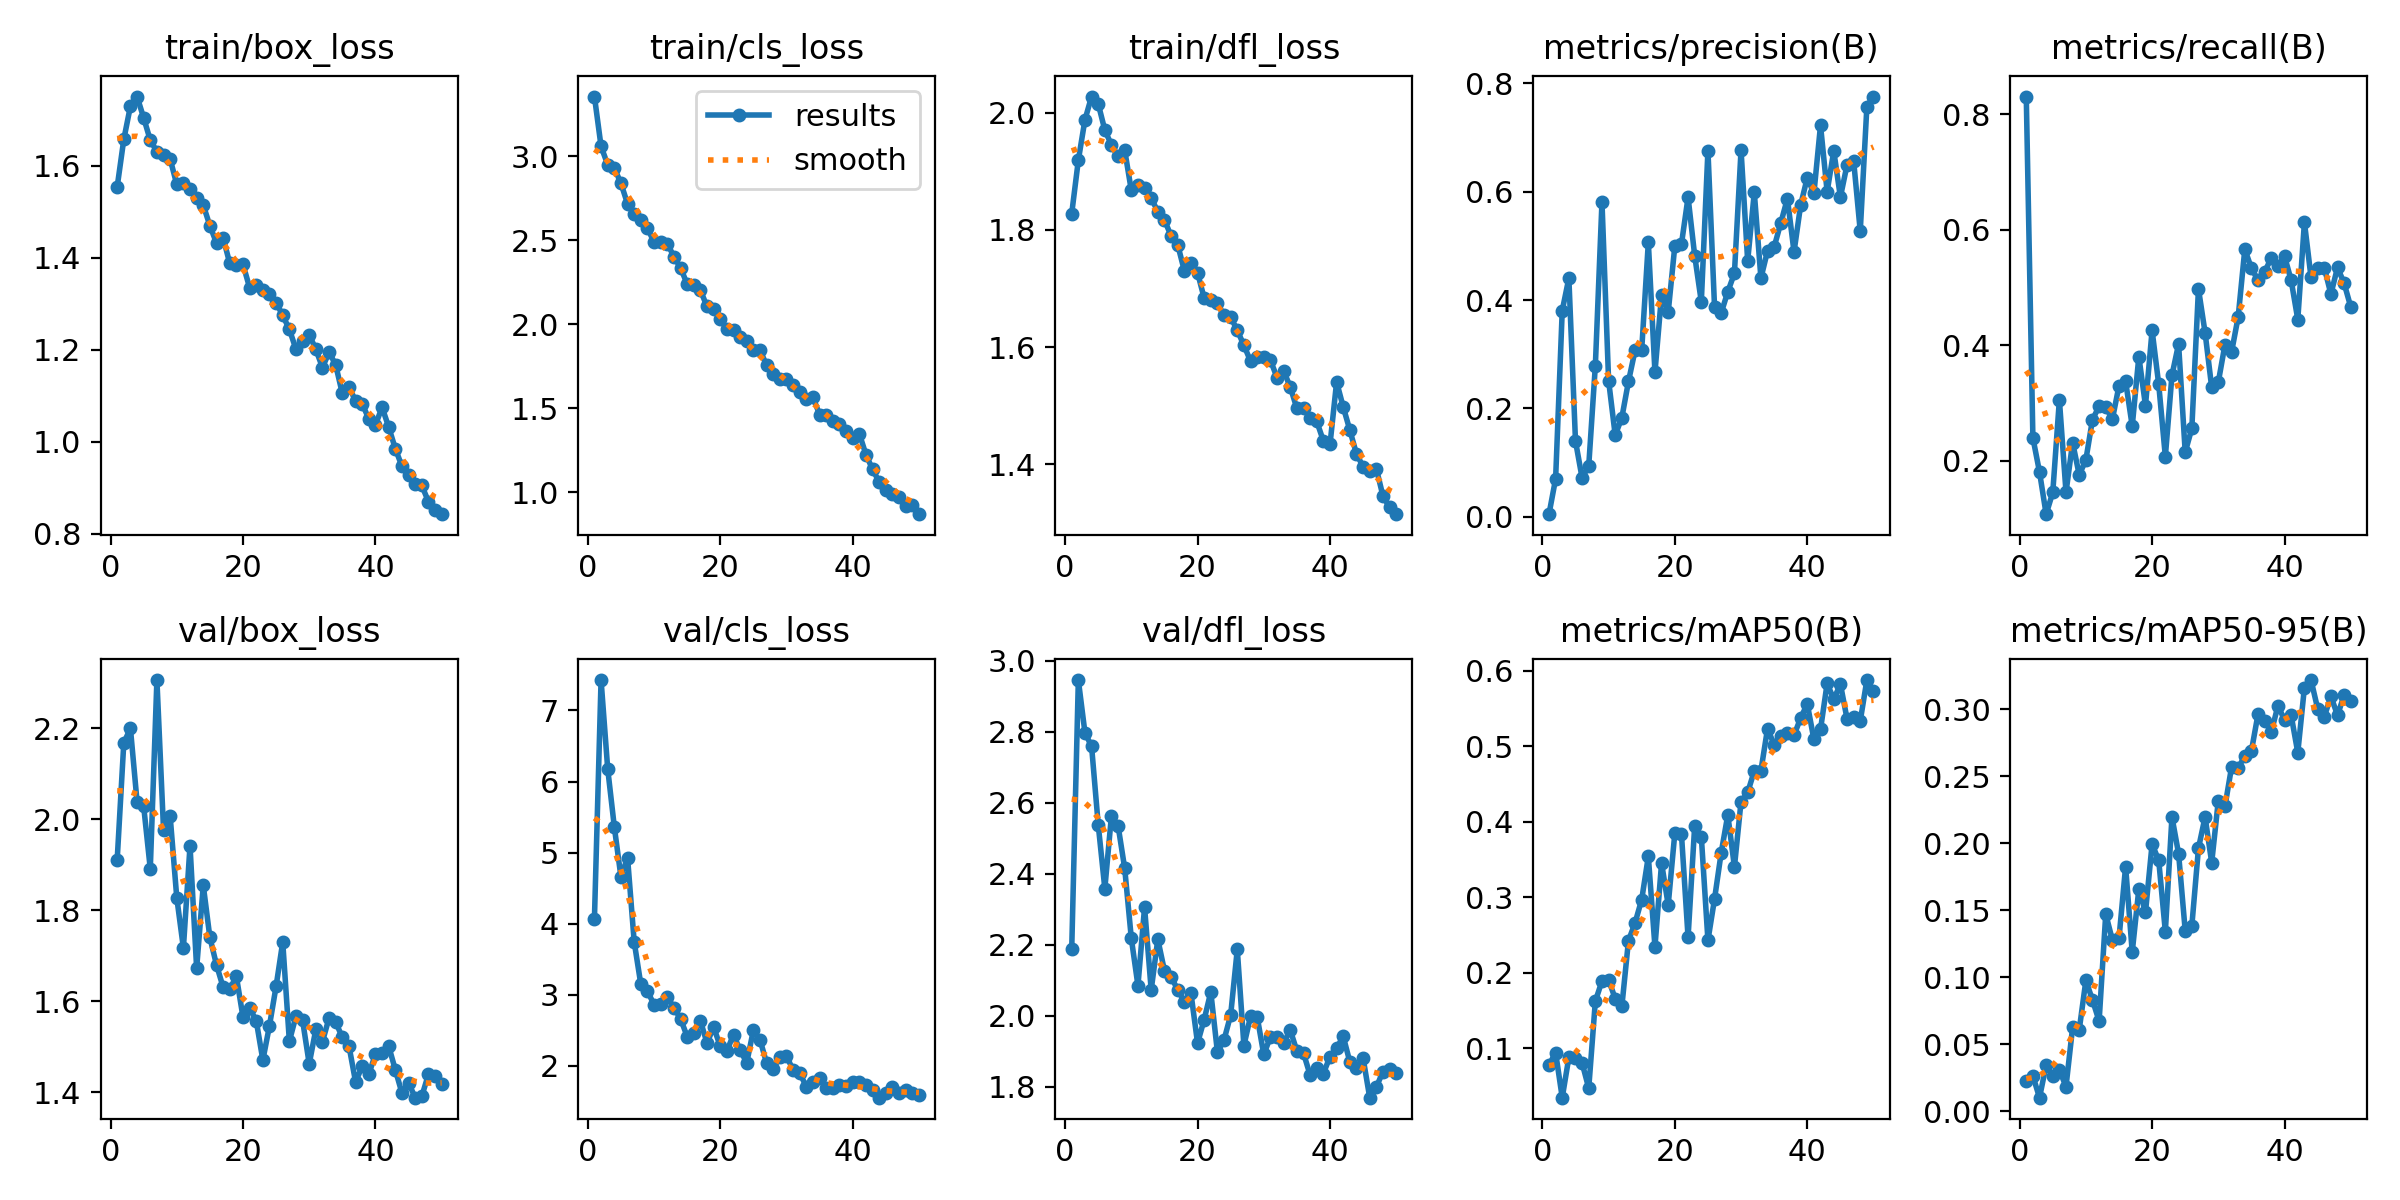


📊 confusion_matrix_normalized.png:


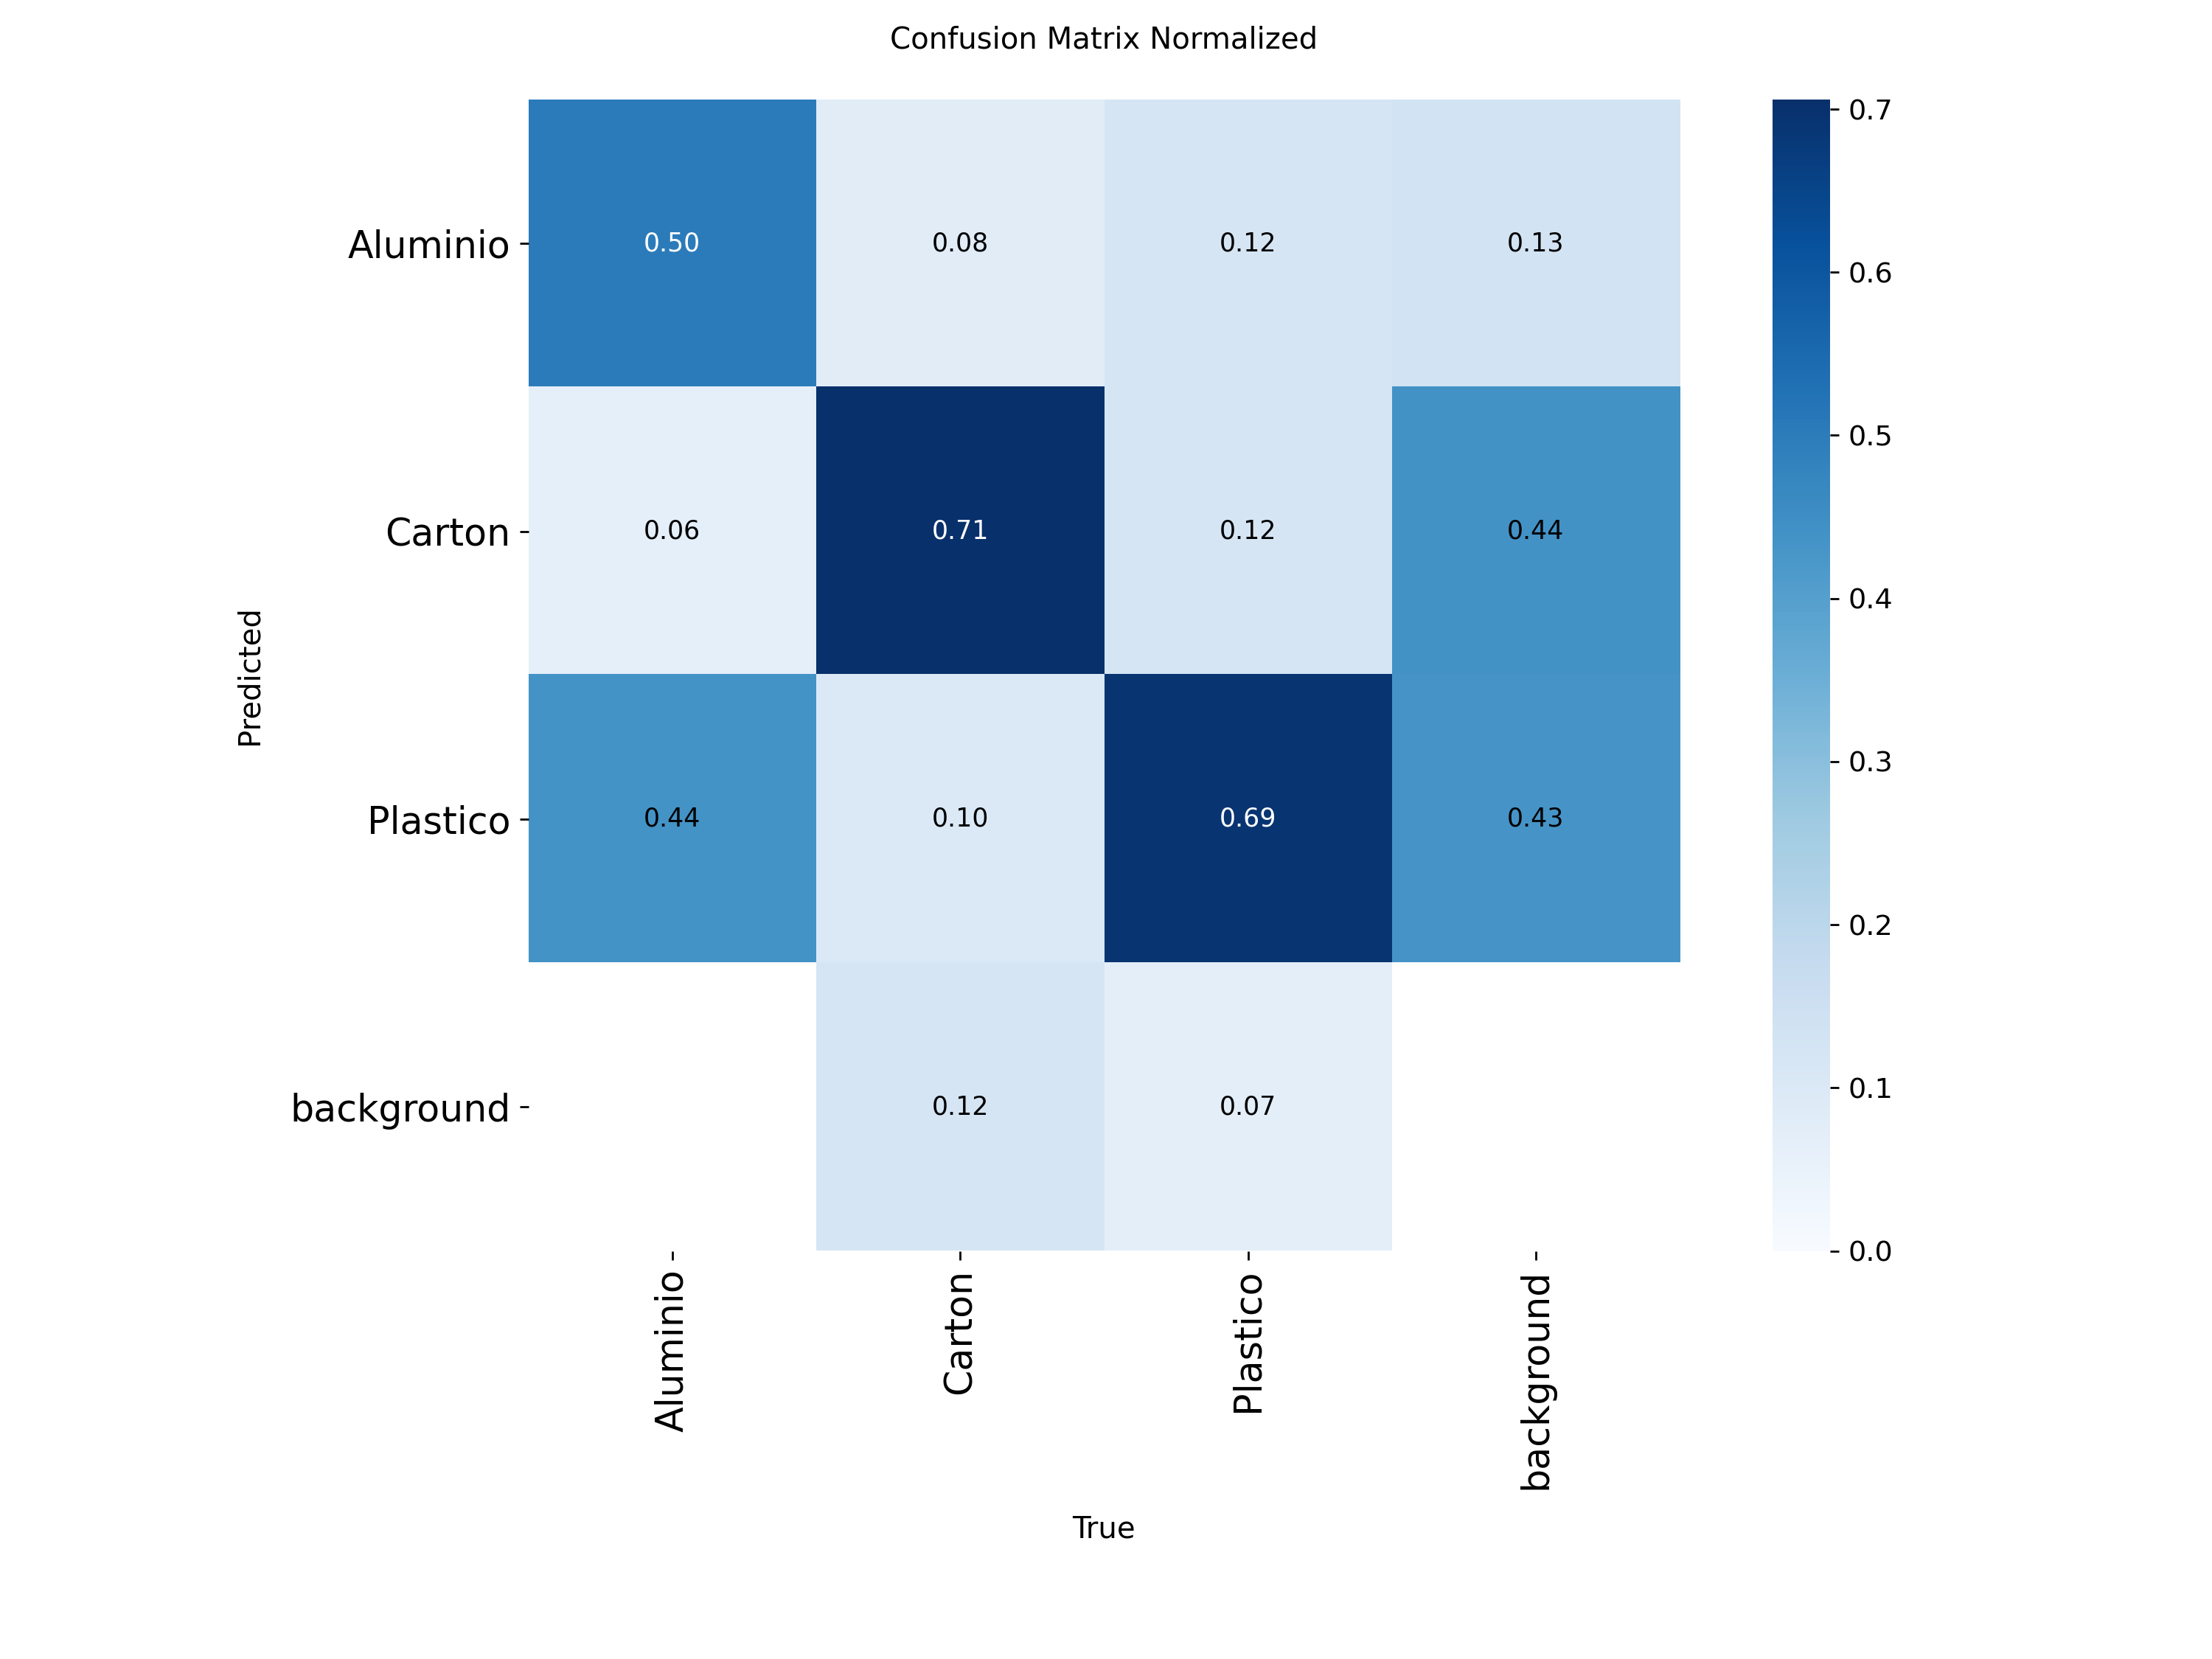

In [ ]:
import pandas as pd
from IPython.display import Image, display

ruta_entreno = "/content/runs/detect/ecoscan_yolo11n"
best_model = YOLO(f"{ruta_entreno}/weights/best.pt")

# Evaluar el modelo
metricas = best_model.val(data=f"{dataset_path}/data.yaml", split="val")

# Crear tabla resumen por clase
resumen_clases = []
for i, nombre in metricas.names.items():
    p, r, ap50, ap = metricas.box.class_result(i)
    resumen_clases.append({
        "Clase": nombre,
        "Precisión (P)": round(p, 3),
        "Recall (R)": round(r, 3),
        "mAP@50": round(ap50, 3),
        "mAP@50-95": round(ap, 3)
    })

df_metricas = pd.DataFrame(resumen_clases)
print("\n=== TABLA DE RENDIMIENTO POR CLASE ===")
display(df_metricas)

# Mostrar gráficos generados por YOLO
for archivo_img in ["results.png", "confusion_matrix_normalized.png", "PR_curve.png"]:
    img_full_path = os.path.join(ruta_entreno, archivo_img)
    if os.path.exists(img_full_path):
        print(f"\n📊 {archivo_img}:")
        display(Image(filename=img_full_path, width=750))

## 6. Fase 6: Prueba de Inferencia y Exportación del Modelo (`best.pt`)
Se comprueba el funcionamiento del detector en imágenes de validación y se descargan los pesos entrenados (`best.pt`) para su integración en la aplicación.

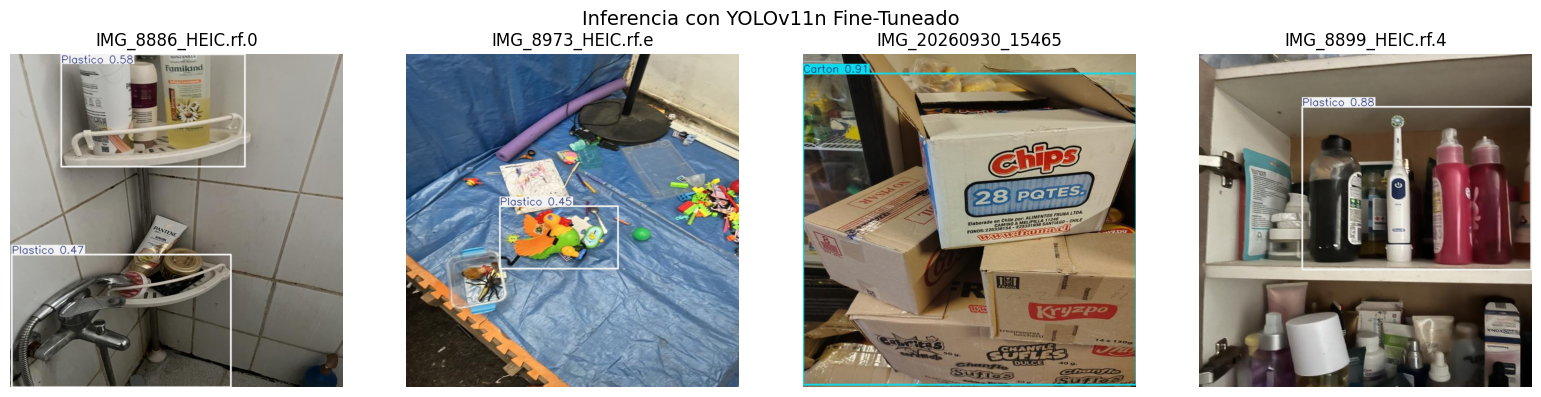

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

# 1. Probar inferencia en 4 imágenes de validación
imgs_test = glob.glob(f"{dataset_path}/valid/images/*.jpg")[:4]

fig, axes = plt.subplots(1, len(imgs_test), figsize=(16, 4))
for ax, img_p in zip(axes, imgs_test):
    pred = best_model.predict(source=img_p, conf=0.40, verbose=False)[0]
    img_plot = cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB)
    ax.imshow(img_plot)
    ax.set_title(os.path.basename(img_p)[:18])
    ax.axis("off")

plt.suptitle("Inferencia con YOLOv11n Fine-Tuneado", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Descargar best.pt a tu computador
peso_final = f"{ruta_entreno}/weights/best.pt"
if os.path.exists(peso_final):
    files.download(peso_final)

### Anexo: distribución espacial de los objetos (análisis complementario del EDA)

Cantidad de objetos por imagen y ubicación de sus centros (mapa de calor) en el conjunto de entrenamiento.

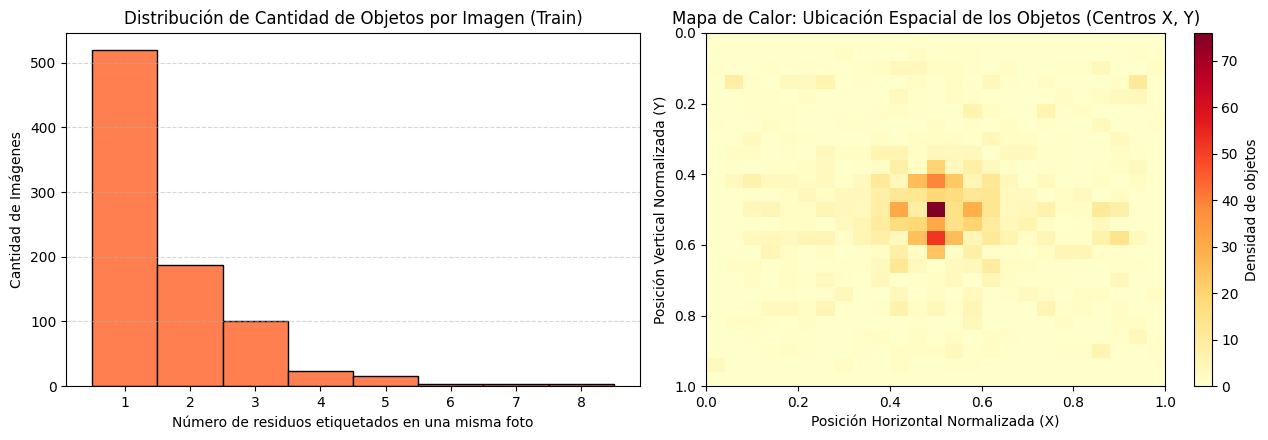

In [ ]:
import glob
import numpy as np
import matplotlib.pyplot as plt

# Analizar cuántos objetos hay por imagen y dónde se concentran espacialmente (Heatmap)
objetos_por_imagen = []
centros_x, centros_y = [], []

for txt_file in glob.glob(f"{dataset_path}/train/labels/*.txt"):
    with open(txt_file, 'r') as f:
        lineas = [l.strip().split() for l in f if l.strip()]
        objetos_por_imagen.append(len(lineas))
        for parts in lineas:
            if len(parts) == 5:
                centros_x.append(float(parts[1]))
                centros_y.append(float(parts[2]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Gráfico 1: Histograma de densidad de objetos por foto
ax[0].hist(objetos_por_imagen, bins=range(1, max(objetos_por_imagen)+2), color='coral', edgecolor='black', align='left')
ax[0].set_title("Distribución de Cantidad de Objetos por Imagen (Train)")
ax[0].set_xlabel("Número de residuos etiquetados en una misma foto")
ax[0].set_ylabel("Cantidad de Imágenes")
ax[0].grid(axis='y', linestyle='--', alpha=0.5)

# Gráfico 2: Mapa de calor de ubicación de los residuos en el encuadre
hb = ax[1].hist2d(centros_x, centros_y, bins=25, cmap='YlOrRd', range=[[0, 1], [0, 1]])
ax[1].invert_yaxis()  # Invertir eje Y para coincidir con coordenadas de imagen (0,0 arriba a la izquierda)
ax[1].set_title("Mapa de Calor: Ubicación Espacial de los Objetos (Centros X, Y)")
ax[1].set_xlabel("Posición Horizontal Normalizada (X)")
ax[1].set_ylabel("Posición Vertical Normalizada (Y)")
plt.colorbar(hb[3], ax=ax[1], label="Densidad de objetos")

plt.tight_layout()
plt.show()

### 6.2 Integración con la aplicación y pruebas de sistema

El modelo (`best.pt`) se integró en un backend **FastAPI** (ruta `/predict`) conectado a una base **MySQL 8** (base `ecoscan`, 14 tablas). Un script de pruebas (`probar_modelo.py`) ejecuta pruebas de humo, casos límite y una prueba del modelo con fotos reales del equipo. Resultados de las ejecuciones del 09-10-2026:

| Prueba | Resultado |
|---|---|
| Pruebas de humo (backend y consultas a MySQL) | 8 de 8 en OK |
| Fotos reales: 30 (10 de cartón, 10 de aluminio, 10 de plástico) | 27 de 30 con resultado exacto (90 %) |
| Cartón | Precisión 1.00, recall 0.90, F1 0.95 |
| Aluminio | Precisión 1.00, recall 1.00, F1 1.00 |
| Plástico | Precisión 0.83, recall 1.00, F1 0.91 |
| Latencia de ida y vuelta por la API (3 ejecuciones) | Promedio 109–112 ms; P95 128–133 ms; entre 10 % y 33 % de las respuestas bajo 100 ms |
| Registro de cada análisis en la tabla `inferencia` | 30 de 30 guardados (26 `OK` y 4 `CONFIANZA_BAJA`) |

**Cómo leer estos números.** Son métricas **por foto** (hay o no hay cada material) y no son comparables con el mAP@50, que mide cajas bien ubicadas. La muestra es pequeña y cada foto tiene un solo material, por lo que los resultados son indicativos y no miden falsas alarmas sobre fondos sin residuos ni fotos con varios materiales.

## 7. Conclusiones Técnicas y Trabajo Futuro (Cierre CRISP-DM)

### 7.1 Preparación de los datos (Fases 2 y 3)
* **Recuperación de integridad del dataset:** La auditoría programática detectó y corrigió `485` archivos con anotaciones poligonales mixtas, transformándolas a *bounding boxes* normalizados $(x_c, y_c, w, h)$. Esto evitó la pérdida de más del $40\%$ de las etiquetas durante la ingesta en el motor de entrenamiento.
* **Balanceo:** Se aplicó *oversampling* con volteo horizontal a las imágenes de entrenamiento con `Aluminio` (`252` imágenes de refuerzo).
* **Caracterización morfológica (MS-COCO):** El análisis de escalas y relación de aspecto describe la geometría de las tres clases y respalda la configuración de los cabezales de detección.

### 7.2 Evaluación del modelo (Fases 4 y 5)
* **Arquitectura:** Se eligió **YOLOv11n** ($\approx 2.58\text{M}$ de parámetros y $\approx 6.4\text{ GFLOPs}$) por su bajo costo computacional y su capacidad de ejecutarse con baja latencia en una aplicación web.
* **Resultados medidos** (conjunto de validación de 61 imágenes y 109 instancias):

| Iteración | Precisión | Recall | mAP@50 | mAP@50-95 |
|---|---|---|---|---|
| 1 (dataset sin limpiar) | 0.798 | 0.561 | 0.638 | 0.357 |
| 2 (dataset limpio + balanceo) | 0.681 | 0.521 | 0.562 | 0.323 |

* **Por clase (iteración 2):** `Aluminio` mAP@50 0.493, `Carton` 0.737 y `Plastico` 0.454.
* **Criterio de éxito:** El criterio $\text{mAP@50} \ge 0.65$ **no se alcanzó** en ninguna de las dos iteraciones (0.638 y 0.562).
* **La iteración 2 no mejoró el mAP@50 global** respecto de la iteración 1. Causas posibles, **por verificar**: (a) el conjunto de validación es pequeño (`16` instancias de `Aluminio`), por lo que la métrica varía mucho; (b) un entrenamiento puede variar entre ejecuciones por la semilla aleatoria; (c) el *oversampling* por volteo no aporta información nueva. Para comprobarlo se propone repetir el entrenamiento con distintas semillas y ampliar el conjunto de validación.

### 7.3 Integración y latencia (Fase 6)
* **Modelo en GPU** (Colab T4, evaluación de validación): $\approx 6.7\text{ ms}$ de preprocesamiento, $10.2\text{ ms}$ de inferencia y $4.3\text{ ms}$ de postprocesamiento por imagen.
* **Aplicación completa** (API FastAPI en el computador del equipo, ida y vuelta HTTP): promedio de $109$–$112\text{ ms}$ y P95 de $128$–$133\text{ ms}$. La inferencia del modelo en GPU toma $\approx 21\text{ ms}$ por imagen; en la aplicación completa, el umbral de $100\text{ ms}$ **no se cumple de forma consistente** en el equipo donde corre el backend. Exportar a ONNX para reducir la latencia queda como trabajo futuro.
* **Pruebas de sistema:** Ver sección 6.2 (27 de 30 fotos con resultado exacto; 30 análisis registrados en MySQL).

### 7.4 Limitaciones y hoja de ruta (siguiente iteración CRISP-DM)
1. **Refinamiento de granularidad en el etiquetado (instancias agrupadas):** El modelo tiende a generar *bounding boxes* envolventes sobre clústeres de objetos contiguos (por ejemplo, varios envases plásticos en estantes o cajas de cartón apiladas), lo que responde a etiquetas grupales en el dataset de origen. Para la **versión 2 del dataset** se re-etiquetarán las instancias de forma individual.
2. **Desbalance de clases (`Aluminio`):** `Aluminio` representa el $21.7\%$ de las instancias de entrenamiento (`316` frente a `572` de `Carton` y `568` de `Plastico`). Se hará una captura dirigida de imágenes de latas bajo distintas condiciones de luz y deformación, que aporte información nueva.
3. **Muestra de pruebas reducida:** Las 30 fotos de la prueba de sistema tienen un solo material cada una. Falta incluir fotos con fondos sin residuos y con varios materiales para medir falsas alarmas.
4. **Cumplimiento del criterio de éxito:** Repetir entrenamientos con distintas semillas, ampliar la validación y evaluar con *Test-Time Augmentation* (TTA) hasta alcanzar $\text{mAP@50} \ge 0.65$.